# Notebook Integrasi Data — Karhutla OKI

Notebook ini membuktikan bahwa tabel panel siap model benar-benar ada, lalu menampilkan peta grid dan menjalankan uji kebocoran fitur.

**Alur folder data:**

```
data/raw/firms/            CSV titik panas NASA FIRMS (per jendela 5 hari)
data/raw/power/            CSV cuaca harian NASA POWER (per titik)
data/external/admin/       batas Kab. OKI (geoBoundaries, BPS 2020)
        |
data/interim/              firms_hotspots.csv, power_daily.csv  (hasil gabung & saring)
        |
data/processed/            dataset.parquet  (panel sel x hari + fitur + label)
```

**Membangun ulang dari awal** (jalankan di terminal dari folder proyek; panduan unduh ada di folder `tutorial/`):

```
python src/download_firms.py
python src/download_power.py
python src/build_dataset.py
```

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

## 1. Ukuran panel final dan ketimpangan kelas

In [2]:
ds = pd.read_parquet(ROOT / "data/processed/dataset.parquet", columns=["cell_id", "date", "fire_today"])
pos = int(ds["fire_today"].sum())
print(f"Total baris      : {len(ds):,}")
print(f"Jumlah sel       : {ds['cell_id'].nunique():,}")
print(f"Rentang tanggal  : {ds['date'].min().date()} s.d. {ds['date'].max().date()} ({ds['date'].nunique():,} hari)")
print(f"Sel-hari berapi  : {pos:,} ({pos / len(ds):.2%})")
print(f"Rasio            : 1 berapi : {round((len(ds) - pos) / pos)} tidak berapi")

Total baris      : 6,796,300
Jumlah sel       : 1,862
Rentang tanggal  : 2015-01-01 s.d. 2024-12-28 (3,650 hari)
Sel-hari berapi  : 36,743 (0.54%)
Rasio            : 1 berapi : 184 tidak berapi


## 2. Cuplikan tabel final (sel 322, 10–14 September 2019)

In [3]:
cols = ["cell_id", "date", "prec", "rain_cum_7", "rh2m_lag1", "t2m_max_lag1",
        "self_fire_7d", "neigh_fire_1d", "fire_today", "fire_h1"]
cuplikan = pd.read_parquet(ROOT / "data/processed/dataset.parquet", columns=cols,
                           filters=[("cell_id", "==", 322)])
cuplikan[(cuplikan.date >= "2019-09-10") & (cuplikan.date <= "2019-09-14")]

,cell_id,date,prec,rain_cum_7,rh2m_lag1,t2m_max_lag1,self_fire_7d,neigh_fire_1d,fire_today,fire_h1
1713,322,2019-09-10,0.0,0.0,84.26,31.61,0,1,0,0
1714,322,2019-09-11,0.0,0.0,84.40,31.37,0,0,0,1
1715,322,2019-09-12,0.0,0.0,83.70,31.82,0,1,1,1
1716,322,2019-09-13,0.0,0.0,82.82,31.66,1,0,1,0
1717,322,2019-09-14,0.0,0.0,80.39,31.41,2,1,0,0


## 3. Peta grid 5 km di atas batas OKI

1862 sel, 684 di dalam OKI, ujung utara belum tercakup 4.9%
tersimpan: C:\File_Kuliah_Semester7\Proyek-Sains-Data\presentasi\aset_m34\peta_grid_5km.png



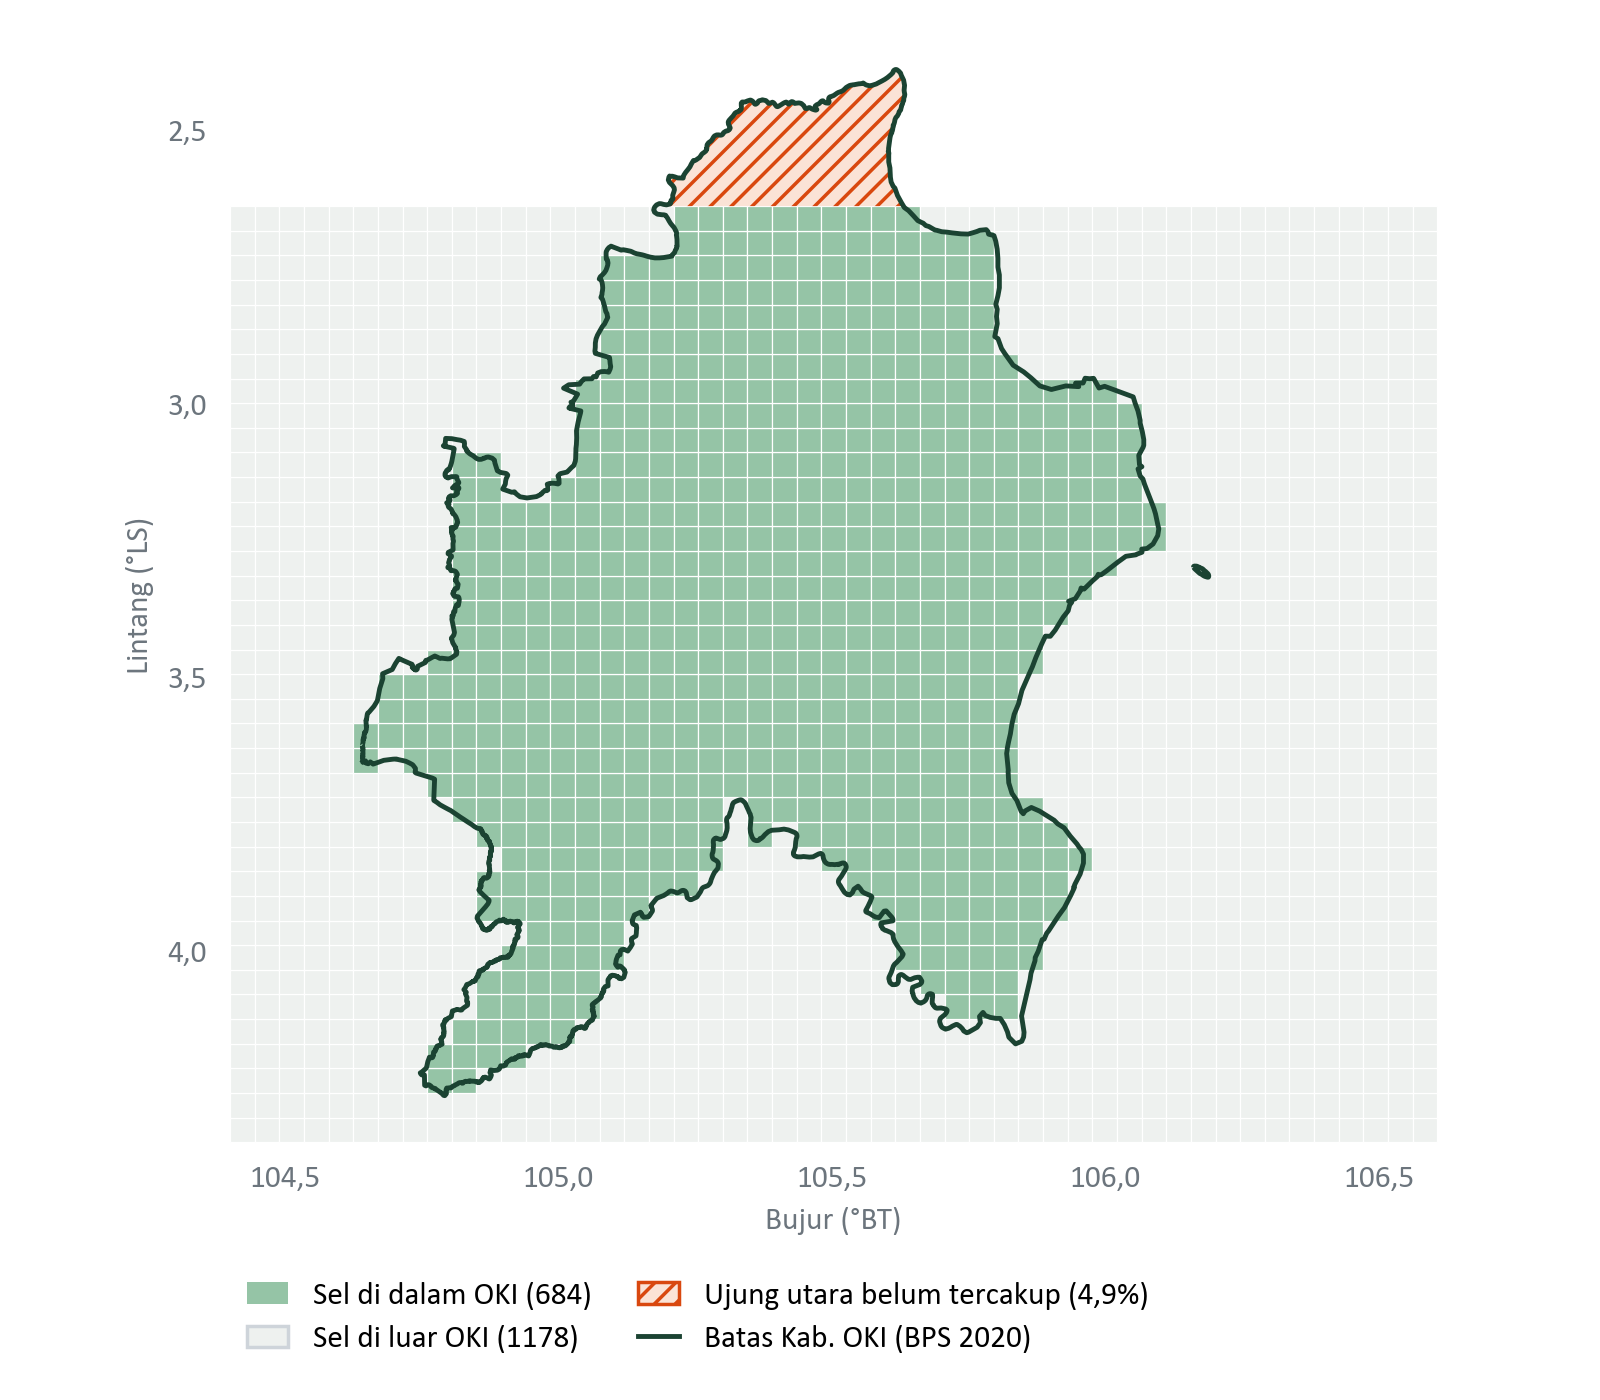

In [4]:
print(subprocess.run([sys.executable, str(ROOT / "scripts/peta_grid.py")],
                     capture_output=True, text=True).stdout)
Image(str(ROOT / "presentasi/aset_m34/peta_grid_5km.png"), width=640)

## 4. Uji kebocoran fitur

In [5]:
hasil = subprocess.run([sys.executable, str(ROOT / "tests/test_leakage.py")],
                       capture_output=True, text=True)
print(hasil.stdout)

Data uji: 284,886 baris (semua sel, 2019-06-01 s.d. 2019-10-31)
PASSED  test_fitur_tidak_berubah_saat_masa_depan_diacak: 34 fitur identik untuk 173,166 baris sampai 2019-09-01
PASSED  test_tanggal_label_selalu_sesudah_tanggal_fitur: fire_h1..h3 = api pada t+1..t+3; max(tanggal fitur) = t < tanggal label
PASSED  test_fitur_riwayat_api_hanya_sampai_kemarin: 6 fitur riwayat api tidak terpengaruh data hari t
3 passed, 0 failed in 9.0s

